# Week 06: IPO & distribution shapes — **self-paced**

**Course:** MATH7810 Python for Data Science (AY2026/27)  
Work through the tasks **in order**. The instructor will **walk around**. Ask if you are stuck after the “If you are stuck” steps.

**This notebook:** Binomial shape, standardizing $Z$, continuity correction, Normal quantile.  


## How to work today

| Step | What you do |
|------|----------------|
| 1 | Read the **task**. |
| 2 | Complete or use the **IPO** comments. |
| 3 | **`Cmd+I` / `Ctrl+I`** → implement comments → **Keep**. |
| 4 | **Read** the code → **Shift+Enter**. |
| 5 | Type the short note and **run** it. |

**If stuck:** Setup ran? Process filled? Then ask — bring what you tried.

## A. IPO reminder

Same habit as Week 5. **Input → Process → Output. AI drafts; **you** verify. The same prompt can differ across runs.


## Setup — run this **first**

**Done when:** the cell prints `Ready` with no error.


In [1]:
# Setup — run this cell first
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm, expon  # short names for Binomial, Normal, Exponential

rng = np.random.default_rng(42)  # reproducible draws for the sim tasks
print("Ready. numpy", np.__version__)  # prints which NumPy you have; __version__ is the name of that version label


Ready. numpy 2.5.3


## Task 1 — Binomial shape vs \(p\)

**Question:** How does the shape of a Binomial distribution differ for different values of \(p\)?

Keep **\(n = 10\)** fixed. Only **\(p\)** changes: **0.2**, **0.5**, **0.9**.

Fill **Process** and **Output**, then Inline Chat.

**Done when:** three bar charts in a row + 1–2 sentences on skewness.

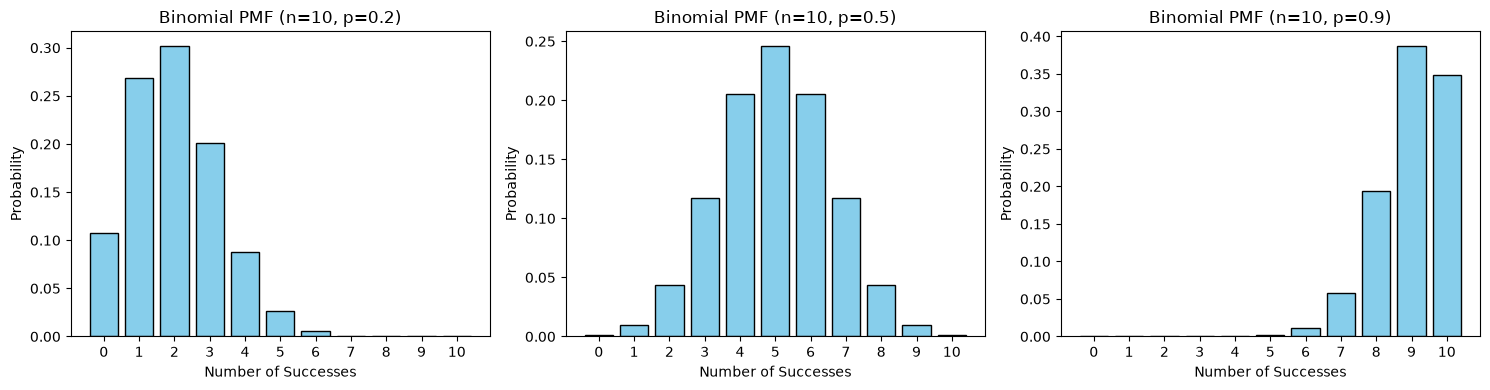

In [11]:
# Task 1 — Binomial PMFs in a row (fixed n, three p)
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: scipy.stats.binom and matplotlib.pyplot.
#
# Process: write python code to generate binomial distribution plot with n=10, define p_values=[0.2, 0.5, 0.9]
#
# Output: a figure with 1 row of 3 binomial distribution
# 
# --- End prompt ---
# Fill Process + Output from the task (3 PMFs side by side). Then Inline Chat.
#
# --- generated / your code below ---
# Binomial PMFs for n=10 and p=0.2, 0.5, 0.9
n = 10
p_values = [0.2, 0.5, 0.9   ]
x = np.arange(0, n + 1) 

fig,axes = plt.subplots(1, 3, figsize=(15, 4),sharex=True)
for ax, p in zip(axes, p_values):
    pmf = binom.pmf(x, n, p)
    ax.bar(x, pmf, color='skyblue', edgecolor='black')
    ax.set_title(f'Binomial PMF (n={n}, p={p})')
    ax.set_xlabel('Number of Successes')
    ax.set_ylabel('Probability')
    ax.set_xticks(x)
plt.tight_layout()  





**Check:** Does the output make sense? Why? Type in the next cell, then **run** it.


In [12]:
# Task 1 — write BETWEEN the triple quotes, then RUN
task1_skew = """
# Skewness (p = 0.2 / 0.5 / 0.9):

"""
print(task1_skew)



# Skewness (p = 0.2 / 0.5 / 0.9):




## Task 2 — Standardizing does **not** create a Normal

**Question:** If we rescale a variable so it has mean 0 and variance 1, is the result always Normal?

Lecture: $Z = (X-\mu)/\sigma$ has **mean 0** and **variance 1**, but is Normal **only if** $X$ is Normal.

Let $X$ be **Exponential** (scale $= 2$). Draw 10,000 values, form $Z$, print mean/var of $Z$, histogram $X$ and $Z$, overlay $N(0,1)$ on $Z$.

Fill **Process** and **Output**, then Inline Chat.

**Done when:** mean of $Z$ is about $0$, variance about $1$, but $Z$ still looks **skewed**.


In [ ]:
# Task 2 — Standardize a non-Normal X
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: numpy, matplotlib.pyplot, rng, and scipy.stats.expon and scipy.stats.norm
#   are already available. 
# Process: let X=rng.exponential(scale=2, size=1000)
#
# Output:
#
# --- End prompt ---
# Fill Process + Output, then Inline Chat. Read the code before running.
#
# --- generated / your code below ---


**Check:** mean/var of \(Z\) vs **shape** of \(Z\). Type 1–2 sentences in the next cell, then run it.


In [ ]:
# Task 2 — write BETWEEN the triple quotes, then RUN
task5_z = """
# Mean/var of Z vs shape of Z:

"""
print(task5_z)


## Task 3 — Normal approximation and continuity correction

**Question:** A Binomial count is a whole number; a Normal curve is continuous. Why do we need a continuity correction when we approximate Binomial probabilities with a Normal?

Each Binomial bar sits on an integer and has **width 1**. The matching Normal area for that bar is from half a unit below to half a unit above — a **continuity correction**.

**Example**: **$n = 16$**, **$p = 0.5$**, so $np = 8 > 5$ and $n(1-p) = 8 > 5$. Let $X$ be Binomial; let $Y$ be Normal with the same mean $np$ and sd $\sqrt{np(1-p)}$.

1. Plot the Binomial PMF bars and overlay the Normal curve.
2. Print three values of $P(X \le 6)$: 
- exact Binomial; 
- Normal **without** correction ($Y \le 6$); 
- Normal **with** correction ($Y \le 6.5$).

Fill **Process** and **Output**, then Inline Chat.

**Done when:** one plot and three printed probabilities. If it helps, add vertical lines at 6 and 6.5 so the half-unit gap is easy to see.


In [ ]:
# Task 3 — Normal approx. + continuity correction
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: numpy, matplotlib.pyplot, scipy.stats.binom and scipy.stats.norm
#   are already imported.
# Process: 
#
#
# Output:
#
# --- End prompt ---
# Fill Process + Output, then Inline Chat. Read the code before running.
#
# --- generated / your code below ---


**Check:** which Normal probability is closer to the exact Binomial $P(X \le 6)$? Type in the next cell, then run it.


In [ ]:
# Task 3 — write BETWEEN the triple quotes, then RUN
task3_cc = """
# Which Normal value is closer, and why add 0.5:

"""
print(task3_cc)


## Task 4 — Normal quantile from a probability

**Question:** In lecture we read a $z$-table *backwards*: given an area, find $z_0$. How do we do that in Python?

Lecture example: find $z_0$ if $P(Z < z_0) = 0.75$ (table: about $0.67$).

`scipy.stats.norm.ppf` is the inverse of `norm.cdf`: given a left-tail probability, it returns the cut-off.

Fill **Process** and **Output**, then Inline Chat.

**Done when:** the printed $z_0$ is close to $0.67$.


In [ ]:
# Task 4 — Normal quantile (ppf)
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: scipy.stats.norm is already imported.
# Process: 
#
#
# Output:
#
# --- End prompt ---
# Fill Process + Output, then Inline Chat. Read the code before running.
#
# --- generated / your code below ---


**Check:** is the printed $z_0$ close to the lecture table value $0.67$? Type in the next cell, then run it.


## Before you leave — checklist
- [ ] Setup ran  
- [ ] **Task 1:** three Binomial PMFs + skewness note  
- [ ] **Task 2:** \(Z\) mean 0, var 1, still not Normal  
- [ ] **Task 3:** $P(X \le 6)$ exact vs Normal without/with $+0.5$ ($n=16$, $p=0.5$); you can say **why** we correct  
- [ ] **Task 4:** $z_0$ for $P(Z<z_0)=0.75$ via `norm.ppf` (about $0.67$)  
